# M11b · Full method: SB-LN + private offsets + offset-weighted GBRA loss + prototype head

**Where we are.** M11a: SB-LN trained from scratch keeps DF/FS, improves FaceShifter by about 1.6 over full LayerNorms at every rank (r = 8: 92.09 vs 90.53 with 5.4× fewer numbers), but loses NeuralTextures (−6 to −11) and some DFD (−0.7 to −1.9). Rank is not the limit (r = 16 ≈ r = 32). NeuralTextures' training CE rises in the last epochs while the others fall, so with few shared directions the other generators' blocks overwrite NT. M11b adds the parts of the method aimed at exactly this.

**Model (deployed).**
- SB-LN adapter as in M11a: γ_l = γ_l⁰ + B_γ a_l, β_l = β_l⁰ + B_β b_l.
- **Prototype head** (M10b: matched the linear head within 0.3 on FaceShifter and DFD): w = normalise(μ_fake − μ_real), m̄ = (μ_real + μ_fake)/2, p(fake) = σ(((z − m̄)·w − b)/τ). Trained: b, τ (2 numbers). μ_real, μ_fake are stored means of training features (buffers, not trained).

**Training only.**
- **Private offsets on the full LayerNorm values** (M10a: GBLA offsets lie ~98% outside the shared directions): a batch of generator g uses γ, β + δ_g, penalty λ‖δ_g‖², λ = 0.01. Discarded after training.
- **GBRA loss** (Generator-Balanced Real-Anchored):

  L = L_M1(CE + 0.1 align + 0.5 uniform) + α · E_real[1 − cos(z, c)] + β · w_g · E_fake∈g[max(0, cos(z, c) − m)] + λ‖δ_g‖²

  c = normalise(μ_real). **w_g = G · softmax_g(‖δ_g‖² / mean_h ‖δ_h‖²)** (no gradient through the weights; all 1 while the offsets are 0). To first order δ_g ≈ −∇L_g/(2λ), so w_g follows each generator's smoothed gradient size: the generator the shared model fits worst gets the most margin pressure.
  The weight multiplies the margin term only: batches are pure (one generator per 225-step block) and Adam rescales gradients, so a weight on the whole loss would largely cancel; on one term it changes the balance inside the loss.
- **Prototypes during training:** running means (momentum 0.99) of the features seen in training, one fake mean per generator (so the last block does not dominate), initialised from 512 un-augmented crops per generator. **After training** they are recomputed exactly from all un-augmented training crops with the deployed model (training data only).

**Fixed before training:** λ = 0.01, α = 0.1, β = 1.0, m = 0.1, τ₀ = 0.1, SB-LN init and everything else as M11a/M4 (10 epochs, seed 0). Nothing is tuned on test data.

**Criteria (stated before training).** Primary: FaceShifter ≥ 92.0 and DFD ≥ 96.0 (the original M11 targets). Secondary, reported: NeuralTextures recovered relative to M11a at the same rank, and the remaining gap to full LayerNorms (87.90).

**Runs:** r = 16 (34,370 deployed trainable numbers), then r = 8 (17,186).

| Section | What it does | Run time |
|---|---|---|
| 1. Setup | settings, imports | seconds |
| 2. Data | crops in RAM, round-robin loader (as M4) | ~1–8 min |
| 3. Model | detector, SB-LN + prototype head + offsets, parameter report | ~1 min |
| 4. Training | checks, two ranks, resumable | ~1.3 h per rank |
| 5. Evaluation | prototype refresh, FF++ test, DFD, UADFV, vs M4 / M11a, criteria | ~10 min per rank |
| 6. Send results back | push this notebook | – |

## 1. Setup

### 1.1 Settings

Training settings are copied from M4/M11a; the method's hyperparameters are fixed here before training. Results go to `runs/m11b/`.

In [1]:
# 1.1 Settings
import os
from pathlib import Path

DATA_ROOT = Path("/nlsasfs/home/isea/isea64/GBLA-Deepfake Detection")
FACES_ROOT = DATA_ROOT / "faces"
INDEX_CSV = DATA_ROOT / "index" / "ffpp_c23.csv"
FACES_DFD = DATA_ROOT / "faces_dfd"
DFD_INDEX = DATA_ROOT / "index" / "dfd_c23.csv"
FACES_UADFV = DATA_ROOT / "faces_uadfv"
UADFV_INDEX = DATA_ROOT / "index" / "uadfv.csv"
RUNS_ROOT = DATA_ROOT / "runs"
M11B_DIR = RUNS_ROOT / "m11b"
M11A_DIR = RUNS_ROOT / "m11a"
M4_DIR = RUNS_ROOT / "m4"

ALL_GENERATORS = ["Deepfakes", "Face2Face", "FaceSwap", "NeuralTextures", "FaceShifter"]
TRAIN_GENERATORS = ["Deepfakes", "Face2Face", "FaceSwap", "NeuralTextures"]
SHORT = {"original": "real", "Deepfakes": "DF", "Face2Face": "F2F", "FaceSwap": "FS",
         "NeuralTextures": "NT", "FaceShifter": "FSh"}
G = len(TRAIN_GENERATORS)

# identical to M4 / M11a
ARCH, PRETRAINED = "ViT-L-14", "openai"
L2_NORM = True
W_UNIFORM, W_ALIGN = 0.5, 0.1
AUGMENT = True
BATCH_SIZE = 128
EPOCHS = 10
CYCLE_EPOCHS = 10
WARMUP_EPOCHS = 1
LR_MAX, LR_MIN = 3e-4, 1e-5
SEED = 0

# M11b method, fixed before training
RANKS = [16, 8]
LAMBDA = 0.01          # private-offset penalty (best lambda of M4)
ALPHA = 0.1            # real compactness around c
BETA = 1.0             # generator-weighted margin
MARGIN = 0.1           # a fake should have cos(z, c) <= MARGIN
EMA = 0.99             # running prototype means
TAU_INIT = 0.1         # head temperature at the start
PROTO_WARM = 512       # un-augmented crops per group to initialise the prototypes
RUN_DFD, RUN_UADFV = True, True
CRITERIA = {"FSh": 92.0, "DFD": 96.0}

# references: (results folder, DFD video AUC from M8b, UADFV video AUC from M9b)
REFS = {"full LayerNorms (M4 λ=∞)": (M4_DIR / f"gbla_laminf_{ARCH}_seed{SEED}", 96.05, 99.38),
        "GBLA λ=0.01 (M4)": (M4_DIR / f"gbla_lam0.01_{ARCH}_seed{SEED}", 96.71, 99.63)}

VAL_FRAMES_PER_VIDEO = 8
CACHE_IN_RAM = True
EVAL_BATCH = 256
GRAD_CHECKPOINTING = False

COMMON_CONFIG = {
    "arch": ARCH, "pretrained": PRETRAINED, "quick_gelu": True, "l2_norm": L2_NORM,
    "w_uniform": W_UNIFORM, "w_align": W_ALIGN, "augment": AUGMENT,
    "batch_size": BATCH_SIZE, "epochs": EPOCHS, "cycle_epochs": CYCLE_EPOCHS,
    "warmup_epochs": WARMUP_EPOCHS, "lr_max": LR_MAX, "lr_min": LR_MIN, "seed": SEED,
    "adapter": "SB-LN: gamma_l = gamma0_l + Bg a_l, beta_l = beta0_l + Bb b_l; Bg, Bb orthonormal x sqrt(width/r), a = b = 0",
    "head": "prototype: sigmoid(((z - mbar) . w - b) / tau), w = normalise(mu_fake - mu_real)",
    "offsets": "delta_g on the LayerNorm values (2 x 50 x 1024 per generator), training only",
    "loss": "L_M1 + alpha E_real[1 - cos(z,c)] + beta w_g E_fake[relu(cos(z,c) - m)] + lambda ||delta_g||^2",
    "weights": "w_g = G softmax(||delta_g||^2 / mean ||delta||^2), no gradient, 1 while deltas are 0",
    "lambda": LAMBDA, "alpha": ALPHA, "beta": BETA, "margin": MARGIN, "ema": EMA,
    "tau_init": TAU_INIT, "proto_warm": PROTO_WARM,
    "reals": "round-robin, fixed for the run, 1/G per generator (as M4)",
    "deployed": "Bg, Bb, A, C, b, tau + prototype buffers recomputed on the training set",
}
assert INDEX_CSV.exists(), f"index not found: {INDEX_CSV}"
for name, (folder, _, _) in REFS.items():
    assert (folder / "results.json").exists(), f"{name} results missing: {folder}"
M11B_DIR.mkdir(parents=True, exist_ok=True)
print("M11b runs go to:", M11B_DIR, "   ranks:", RANKS)

M11b runs go to: /nlsasfs/home/isea/isea64/GBLA-Deepfake Detection/runs/m11b    ranks: [16, 8]


### 1.2 Imports and environment

`os.cpu_count()` reports the whole node (256), but the job may only use the CPUs in its affinity mask and cgroup quota; the loader uses that number. Free RAM decides in 2.2 how many crops can be kept in memory.

In [2]:
# 1.2 Imports and environment
import json, math, random, time
from collections import defaultdict
from concurrent.futures import ThreadPoolExecutor

import matplotlib.pyplot as plt
import numpy as np
import open_clip
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from PIL import Image
from torch.utils.data import DataLoader, Dataset, Sampler
from torchvision import tv_tensors
from torchvision.io import ImageReadMode, read_image
from torchvision.transforms import v2 as T
from tqdm.auto import tqdm

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
assert torch.cuda.is_available(), "M11b needs the GPU"
DEVICE = "cuda"


def usable_cpus():
    """CPUs this job may use: the affinity mask and the cgroup CPU quota."""
    n = len(os.sched_getaffinity(0))
    for quota_file, period_file in [("/sys/fs/cgroup/cpu.max", None),
                                    ("/sys/fs/cgroup/cpu/cpu.cfs_quota_us", "/sys/fs/cgroup/cpu/cpu.cfs_period_us")]:
        try:
            if period_file is None:
                quota, period = Path(quota_file).read_text().split()
            else:
                quota, period = Path(quota_file).read_text().strip(), Path(period_file).read_text().strip()
            if quota not in ("max", "-1"):
                n = min(n, max(1, int(quota) // int(period)))
        except (OSError, ValueError):
            pass
    return n


def available_memory_gb():
    """Free RAM for this job: the smaller of MemAvailable and the cgroup limit minus non-cache usage."""
    candidates = []
    try:
        meminfo = dict(line.split(":", 1) for line in Path("/proc/meminfo").read_text().splitlines())
        candidates.append(int(meminfo["MemAvailable"].split()[0]) * 1024)
    except (OSError, KeyError, ValueError):
        pass
    for limit_file, usage_file, stat_file, cache_key in [
            ("/sys/fs/cgroup/memory.max", "/sys/fs/cgroup/memory.current", "/sys/fs/cgroup/memory.stat", "file"),
            ("/sys/fs/cgroup/memory/memory.limit_in_bytes", "/sys/fs/cgroup/memory/memory.usage_in_bytes",
             "/sys/fs/cgroup/memory/memory.stat", "cache")]:
        try:
            limit = Path(limit_file).read_text().strip()
            if not limit.isdigit() or int(limit) >= 1 << 60:
                continue
            usage = int(Path(usage_file).read_text().strip())
            stat = dict(line.split() for line in Path(stat_file).read_text().splitlines())
            candidates.append(int(limit) - usage + int(stat.get(cache_key, 0)))
        except (OSError, ValueError):
            pass
    return min(candidates) / 1e9 if candidates else 0.0


CPUS = usable_cpus()
NUM_WORKERS = max(1, min(16, CPUS - 1))     # one CPU stays with the training process
torch.set_num_threads(2)

pd.Series({
    "torch": torch.__version__,
    "torchvision": torchvision.__version__,
    "open_clip": open_clip.__version__,
    "GPU": torch.cuda.get_device_name(0),
    "CPU cores on the node": os.cpu_count(),
    "CPUs usable by this job": CPUS,
    "data loader workers": NUM_WORKERS,
    "free RAM for this job (GB)": round(available_memory_gb(), 1),
}, name="value").to_frame()

/nlsasfs/home/isea/isea64/venv_jupyter/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,value
torch,2.6.0+cu124
torchvision,0.21.0+cu124
open_clip,3.3.0
GPU,NVIDIA A100-SXM4-40GB
CPU cores on the node,256
CPUs usable by this job,8
data loader workers,7
free RAM for this job (GB),1033.8


## 2. Data

### 2.1 Index and subsets

Same splits as M1: train = real + the 4 training generators (115,200 crops); test = real + all 5 generators, FaceShifter unseen. Val keeps 8 evenly spaced frames of each video (5,600 crops instead of 22,400). Val only monitors training, so this changes no trained model; val numbers are therefore not identical to M1's.

In [3]:
# 2.1 Index and subsets
index = pd.read_csv(INDEX_CSV, dtype={"video_id": str, "target_id": str, "source_id": str},
                    keep_default_na=False)
CATEGORIES = ["original"] + ALL_GENERATORS
GEN_CODE = {g: k for k, g in enumerate(CATEGORIES)}


def subset(split, generators):
    keep = (index.split == split) & index.generator.isin(["original", *generators])
    return index[keep].reset_index(drop=True)


train_df = subset("train", TRAIN_GENERATORS)
val_all = subset("val", TRAIN_GENERATORS)
frames_per_video = int(val_all.groupby(["generator", "video_id"]).size().max())
keep_every = max(1, frames_per_video // VAL_FRAMES_PER_VIDEO)
frame_rank = val_all.groupby(["generator", "video_id"]).frame_idx.rank(method="first").astype(int) - 1
val_df = val_all[frame_rank % keep_every == 0].reset_index(drop=True)
test_df = subset("test", ALL_GENERATORS)

display(pd.DataFrame({name: df.groupby("generator").size().reindex(CATEGORIES)
                      for name, df in [("train", train_df), ("val (subsampled)", val_df), ("test", test_df)]}
                     ).fillna(0).astype(int))

,train,val (subsampled),test
generator,,,
original,23040,1120,4480
Deepfakes,23040,1120,4480
Face2Face,23040,1120,4480
FaceSwap,23040,1120,4480
NeuralTextures,23040,1120,4480
FaceShifter,0,0,4480


### 2.2 Decoded crops in RAM

Reading 115,200 small PNG files per epoch from the network file system was the likely M1 bottleneck. Here every crop is read once per session into one uint8 array (224 × 224 × 3 bytes per crop: train 17.3 GB, val 0.8 GB, test 4.0 GB), in the order train → val → test, as long as it fits in 60% of free RAM. Sets that don't fit are read from disk as in M1. Nothing is written to disk. The printed read speed also tells us how fast the file system is.

In [4]:
# 2.2 Decoded crops in RAM
def load_images(df, desc):
    """Decodes every crop of an index slice into one uint8 array (N, H, W, 3), using threads."""
    paths = [FACES_ROOT / p for p in df.path]
    first = np.asarray(Image.open(paths[0]).convert("RGB"))
    out = np.empty((len(paths), *first.shape), dtype=np.uint8)

    def work(k):
        out[k] = np.asarray(Image.open(paths[k]).convert("RGB"))

    with ThreadPoolExecutor(max_workers=min(32, 4 * CPUS)) as pool:
        list(tqdm(pool.map(work, range(len(paths))), total=len(paths), desc=desc, mininterval=5))
    return out


images = {}
budget = 0.6 * available_memory_gb()
for name, df in [("train", train_df), ("val", val_df), ("test", test_df)]:
    need = len(df) * 224 * 224 * 3 / 1e9
    if CACHE_IN_RAM and need <= budget:
        t = time.time()
        images[name] = load_images(df, f"{name} crops -> RAM")
        budget -= need
        sec = time.time() - t
        print(f"{name}: {len(df):,} crops, {need:.1f} GB in RAM, {sec / 60:.1f} min ({len(df) / sec:.0f} crops/s from disk)")
    else:
        images[name] = None
        print(f"{name}: read from disk during training (needs {need:.1f} GB, RAM budget left {budget:.1f} GB)")

train crops -> RAM: 100%|██████████| 115200/115200 [00:04<00:00, 24983.16it/s]


train: 115,200 crops, 17.3 GB in RAM, 1.1 min (1708 crops/s from disk)


val crops -> RAM: 100%|██████████| 5600/5600 [00:03<00:00, 1652.81it/s]


val: 5,600 crops, 0.8 GB in RAM, 0.1 min (1515 crops/s from disk)


test crops -> RAM: 100%|██████████| 26880/26880 [00:07<00:00, 3486.17it/s]

test: 26,880 crops, 4.0 GB in RAM, 0.3 min (1641 crops/s from disk)


### 2.3 Round-robin loader

Each training generator owns all of its fakes and a **fixed** 1/G slice of the training reals (round-robin by row order, seed 0). A real crop is never shared across generators, so Σ_g L_g is one pass over the M1 training set. One epoch = G blocks of 225 steps = 900 steps, the same number of images as one M1 epoch. Block order inside an epoch is shuffled by (seed, epoch); order inside a block depends only on (seed, generator, epoch).

In [5]:
# 2.3 Round-robin loader
CLIP_MEAN = (0.48145466, 0.4578275, 0.40821073)
CLIP_STD = (0.26862954, 0.26130258, 0.27577711)


def make_transform(train):
    steps = []
    if train and AUGMENT:
        steps += [
            T.RandomHorizontalFlip(0.5),
            T.RandomAffine(degrees=10, translate=(0.1, 0.1), scale=(0.9, 1.1)),
            T.RandomApply([T.GaussianBlur(kernel_size=7, sigma=(0.1, 2.0))], p=0.1),
            T.ColorJitter(brightness=0.1, contrast=0.1),
            T.JPEG(quality=(40, 100)),
        ]
    steps += [T.ToDtype(torch.float32, scale=True), T.Normalize(CLIP_MEAN, CLIP_STD)]
    return T.Compose(steps)


class FaceDataset(Dataset):
    def __init__(self, df, train, images=None):
        self.paths = [str(FACES_ROOT / p) for p in df.path]
        self.images = images
        self.labels = torch.tensor(df.label.values, dtype=torch.long)
        self.gens = torch.tensor(df.generator.map(GEN_CODE).values, dtype=torch.long)
        self.transform = make_transform(train)

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        if self.images is not None:
            image = torch.from_numpy(np.array(self.images[i])).permute(2, 0, 1)
        else:
            image = read_image(self.paths[i], mode=ImageReadMode.RGB)
        return self.transform(tv_tensors.Image(image)).as_subclass(torch.Tensor), self.labels[i], self.gens[i]


class RoundRobinSampler(Sampler):
    """One epoch = one block per training generator, in an order fixed by (seed, epoch)."""

    def __init__(self, df, seed):
        self.seed = seed
        self.epoch = 0
        gen = df.generator.values
        real_idx = np.flatnonzero(gen == "original")
        # fixed split: real row r goes to generator r % G
        self.blocks = {}
        for k, g in enumerate(TRAIN_GENERATORS):
            fakes = np.flatnonzero(gen == g)
            reals = real_idx[k::G][: len(fakes) // G]
            self.blocks[g] = (fakes, reals)
        self.n_per = len(self.blocks[TRAIN_GENERATORS[0]][0]) + len(self.blocks[TRAIN_GENERATORS[0]][1])

    def set_epoch(self, epoch):
        self.epoch = epoch

    def __iter__(self):
        order_rng = np.random.default_rng([self.seed, self.epoch, 1])
        gens = list(TRAIN_GENERATORS)
        order_rng.shuffle(gens)
        out = []
        for g in gens:
            fakes, reals = self.blocks[g]
            rng = np.random.default_rng([self.seed, ALL_GENERATORS.index(g), self.epoch])
            out.extend(rng.permutation(np.concatenate([fakes, reals])).tolist())
        return iter(out)

    def __len__(self):
        return self.n_per * G


train_ds = FaceDataset(train_df, train=True, images=images["train"])
train_sampler = RoundRobinSampler(train_df, SEED)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, sampler=train_sampler, drop_last=True,
                          num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=True, prefetch_factor=4)
owned = {SHORT[g]: (len(f), len(r)) for g, (f, r) in train_sampler.blocks.items()}
print("fakes / reals owned by each generator:", owned)
print(f"steps per epoch: {len(train_loader)}  (M1 was 900);  workers: {NUM_WORKERS}")
assert len(train_loader) == 900, len(train_loader)

fakes / reals owned by each generator: {'DF': (23040, 5760), 'F2F': (23040, 5760), 'FS': (23040, 5760), 'NT': (23040, 5760)}
steps per epoch: 900  (M1 was 900);  workers: 7


### 2.4 Data-loading speed

Same measurement as M4. The printed hours are for **one rank** (10 epochs × 900 steps).

In [6]:
# 2.4 Data-loading speed
def loader_rate(loader, n_batches=30):
    """Steady-state images/s after the pre-fetched batches are used up."""
    it = iter(loader)
    for _ in range(NUM_WORKERS * 4 + 2):
        next(it)
    t = time.time()
    for _ in range(n_batches):
        next(it)
    rate = n_batches * loader.batch_size / (time.time() - t)
    del it
    return rate


t = time.time()
for i in range(200):
    train_ds[i]
ms_per_crop = (time.time() - t) / 200 * 1000
load_speed = loader_rate(train_loader)
GPU_SPEED_M1 = 253
speed = min(load_speed, GPU_SPEED_M1)
pd.Series({
    "CPU time per augmented crop, one process (ms)": round(ms_per_crop, 1),
    "data loading speed (img/s)": round(load_speed),
    "GPU training speed in M1 (img/s)": GPU_SPEED_M1,
    "bottleneck": "GPU" if load_speed >= GPU_SPEED_M1 else "data loading",
    "estimated minutes per epoch (training part)": round(len(train_loader) * BATCH_SIZE / speed / 60, 1),
    f"estimated hours per rank ({EPOCHS} epochs)": round(EPOCHS * len(train_loader) * BATCH_SIZE / speed / 3600, 1),
}, name="value").to_frame()

,value
"CPU time per augmented crop, one process (ms)",3.5
data loading speed (img/s),1132
GPU training speed in M1 (img/s),253
bottleneck,GPU
estimated minutes per epoch (training part),7.6
estimated hours per rank (10 epochs),1.3


## 3. Model

### 3.1 Detector

Same CLIP encoder as M1/M4. The 104,450 effective numbers are still written by `set_flat`; the LayerNorm part comes from SB-LN (+ δ_g during training). The detector's linear head is **not used** in M11b (the prototype head replaces it); its slots in θ stay at their initial values and receive no gradient.

In [7]:
# 3.1 Detector (as in M1)
class Detector(nn.Module):
    def __init__(self):
        super().__init__()
        encoder = open_clip.create_model(ARCH, pretrained=PRETRAINED, force_quick_gelu=True).visual
        encoder.proj = None                      # keep the 1024-d CLS token
        self.encoder = encoder
        self.head = nn.Linear(encoder.transformer.width, 2)

    def forward(self, x):
        """Returns (logits, L2-normalized features)."""
        feats = self.encoder(x).float()
        f = F.normalize(feats, dim=-1)
        return self.head(f if L2_NORM else feats), f


torch.manual_seed(SEED)
model = Detector().to(DEVICE)
model.requires_grad_(False)
for m in model.encoder.modules():
    if isinstance(m, nn.LayerNorm):
        m.requires_grad_(True)
model.head.requires_grad_(True)
model.encoder.set_grad_checkpointing(GRAD_CHECKPOINTING)

PARAMS = [(n, p) for n, p in model.named_parameters() if p.requires_grad]
PARAM_NAMES = [n for n, _ in PARAMS]
P = sum(p.numel() for _, p in PARAMS)


def get_flat():
    return torch.cat([p.detach().reshape(-1) for _, p in PARAMS]).float()


@torch.no_grad()
def set_flat(theta):
    offset = 0
    for _, p in PARAMS:
        n = p.numel()
        p.copy_(theta[offset:offset + n].view_as(p))
        offset += n


def flat_grad():
    return torch.cat([p.grad.reshape(-1) for _, p in PARAMS]).float()


def flat_from_state(state):
    return torch.cat([state[n].reshape(-1).float() for n in PARAM_NAMES]).to(DEVICE)


def trainable_state():
    return {n: p.detach().cpu().clone() for n, p in PARAMS}


THETA0 = get_flat().clone()
print(f"trainable numbers P = {P:,}")
if ARCH == "ViT-L-14":
    assert P == 104_450

trainable numbers P = 104,450


### 3.2 SB-LN, prototype head, private offsets; parameter report

`M11bState` holds everything trained: B_γ, B_β, A, C (SB-LN), b and ρ = log τ (head), one offset δ_g ∈ ℝ^{2×50×1024} per generator, and the prototype means (one real, one fake per generator). `theta(g)` rebuilds the effective numbers for generator g (θ_s + δ_g on the LayerNorm values); `theta()` is the deployed θ_s.

In [8]:
# 3.2 SB-LN + prototype head + private offsets
WIDTH = model.encoder.transformer.width
SLICES, offset = {}, 0
for n, p in PARAMS:
    SLICES[n] = slice(offset, offset + p.numel())
    offset += p.numel()
LN_MODULES = [n[:-len(".weight")] for n in PARAM_NAMES if n.endswith(".weight") and not n.startswith("head")]
N_LN = len(LN_MODULES)
assert N_LN == 50, N_LN


def rows_index(suffix):
    return torch.stack([torch.arange(SLICES[m + suffix].start, SLICES[m + suffix].stop) for m in LN_MODULES]).to(DEVICE)


GAMMA_IDX, BETA_IDX = rows_index(".weight"), rows_index(".bias")
G0, B0 = THETA0[GAMMA_IDX].clone(), THETA0[BETA_IDX].clone()
HEAD_SLOTS = sum(p.numel() for n, p in PARAMS if n.startswith("head"))


def deployed_count(r):
    return 2 * WIDTH * r + 2 * N_LN * r + 2


class M11bState:
    SB_KEYS = ("Bg", "Bb", "A", "C")

    def __init__(self, r, seed=SEED):
        self.r = r
        gen = torch.Generator().manual_seed(seed)
        scale = math.sqrt(WIDTH / r)

        def basis():
            q, _ = torch.linalg.qr(torch.randn(WIDTH, r, generator=gen))
            return (q * scale).to(DEVICE)

        self.p = {"Bg": basis(), "Bb": basis(),
                  "A": torch.zeros(N_LN, r, device=DEVICE), "C": torch.zeros(N_LN, r, device=DEVICE),
                  "b": torch.zeros((), device=DEVICE), "rho": torch.full((), math.log(TAU_INIT), device=DEVICE)}
        self.delta = {g: torch.zeros(2, N_LN, WIDTH, device=DEVICE) for g in TRAIN_GENERATORS}
        self.proto = {"real": torch.zeros(WIDTH, device=DEVICE), "n_real": 0,
                      "fake": {g: torch.zeros(WIDTH, device=DEVICE) for g in TRAIN_GENERATORS},
                      "n_fake": {g: 0 for g in TRAIN_GENERATORS}}

    def deployed_numel(self):
        return sum(v.numel() for v in self.p.values())

    def theta(self, g=None, p=None, delta=None):
        p = self.p if p is None else p
        gam = G0 + p["A"] @ p["Bg"].T
        bet = B0 + p["C"] @ p["Bb"].T
        if g is not None:
            d = self.delta[g] if delta is None else delta
            gam, bet = gam + d[0], bet + d[1]
        t = THETA0.clone()
        t[GAMMA_IDX] = gam
        t[BETA_IDX] = bet
        return t

    def sb_grads(self, grad):
        """Chain rule from the gradient on the effective numbers to SB-LN; also the gradient on the LayerNorm values."""
        Gg, Gb, p = grad[GAMMA_IDX], grad[BETA_IDX], self.p
        sb = {"A": Gg @ p["Bg"], "Bg": Gg.T @ p["A"], "C": Gb @ p["Bb"], "Bb": Gb.T @ p["C"]}
        return sb, torch.stack([Gg, Gb])

    def weights(self):
        n2 = torch.stack([self.delta[g].pow(2).sum() for g in TRAIN_GENERATORS])
        if float(n2.mean()) == 0.0:
            return {g: 1.0 for g in TRAIN_GENERATORS}
        w = G * torch.softmax(n2 / n2.mean(), dim=0)
        return {g: float(w[k]) for k, g in enumerate(TRAIN_GENERATORS)}

    def prototypes(self, proto=None):
        proto = self.proto if proto is None else proto
        fakes = [proto["fake"][g] for g in TRAIN_GENERATORS if proto["n_fake"][g] > 0]
        assert proto["n_real"] > 0 and fakes, "prototypes not initialised"
        mu_r, mu_f = proto["real"], torch.stack(fakes).mean(0)
        return {"w": F.normalize(mu_f - mu_r, dim=0), "mbar": (mu_r + mu_f) / 2, "c": F.normalize(mu_r, dim=0)}

    @torch.no_grad()
    def update_prototypes(self, z, y, g):
        def ema(old, new, n):
            return new.clone() if n == 0 else EMA * old + (1 - EMA) * new
        real = y == 0
        if real.any():
            self.proto["real"] = ema(self.proto["real"], z[real].mean(0), self.proto["n_real"])
            self.proto["n_real"] += 1
        if (~real).any():
            self.proto["fake"][g] = ema(self.proto["fake"][g], z[~real].mean(0), self.proto["n_fake"][g])
            self.proto["n_fake"][g] += 1

    def proto_cpu(self, proto=None):
        proto = self.proto if proto is None else proto
        return {"real": proto["real"].cpu(), "n_real": proto["n_real"],
                "fake": {g: v.cpu() for g, v in proto["fake"].items()}, "n_fake": dict(proto["n_fake"])}

    def save(self):
        return {"rank": self.r, "phi": {k: v.detach().cpu() for k, v in self.p.items()},
                "delta": {g: v.cpu() for g, v in self.delta.items()}, "proto": self.proto_cpu(),
                "theta": self.theta().cpu()}

    def load(self, obj):
        assert obj["rank"] == self.r, (obj["rank"], self.r)
        self.p = {k: obj["phi"][k].to(DEVICE).float() for k in self.p}
        self.delta = {g: obj["delta"][g].to(DEVICE).float() for g in TRAIN_GENERATORS}
        pr = obj["proto"]
        self.proto = {"real": pr["real"].to(DEVICE), "n_real": pr["n_real"],
                      "fake": {g: pr["fake"][g].to(DEVICE) for g in TRAIN_GENERATORS}, "n_fake": dict(pr["n_fake"])}


TOTAL_ALL = sum(p.numel() for p in model.parameters())
FROZEN = TOTAL_ALL - HEAD_SLOTS          # CLIP encoder incl. gamma0 / beta0; the unused linear head is not part of the model
rows = [{"model": "full LayerNorms + linear head (M4)", "trainable (deployed)": P, "frozen": TOTAL_ALL - P,
         "total": TOTAL_ALL, "stored during training": P * (1 + G), "buffers": 0}]
for r in sorted(RANKS):
    assert M11bState(r).deployed_numel() == deployed_count(r)
    rows.append({"model": f"M11b SB-LN r={r} + prototype head", "trainable (deployed)": deployed_count(r),
                 "frozen": FROZEN, "total": FROZEN + deployed_count(r),
                 "stored during training": deployed_count(r) + G * 2 * N_LN * WIDTH, "buffers": 2 * WIDTH})
param_report = pd.DataFrame(rows).set_index("model")
param_report["trainable %"] = (100 * param_report["trainable (deployed)"] / param_report["total"]).round(4)
param_report["vs M4"] = (P / param_report["trainable (deployed)"]).round(2).astype(str) + "x fewer"
display(param_report)
print("buffers = stored prototype means (mu_real, mu_fake), not trained")

,trainable (deployed),frozen,total,stored during training,buffers,trainable %,vs M4
model,,,,,,,
full LayerNorms + linear head (M4),104450,303077376,303181826,522250,0,0.0345,1.0x fewer
M11b SB-LN r=8 + prototype head,17186,303179776,303196962,426786,2048,0.0057,6.08x fewer
M11b SB-LN r=16 + prototype head,34370,303179776,303214146,443970,2048,0.0113,3.04x fewer


buffers = stored prototype means (mu_real, mu_fake), not trained


## 4. Training

### 4.1 Loss, step, prediction

One step on a pure batch of generator g: prototypes and w_g are read (no gradient), θ_s + δ_g is written into the model, forward → GBRA loss → backward; the gradient on the LayerNorm values goes to SB-LN by the chain rule and to δ_g directly (+ 2λδ_g); b, ρ get autograd gradients; one Adam step per tensor (own step counter). Then the running prototypes are updated with the batch features.

In [9]:
# 4.1 Helpers
MEAN_GPU = torch.tensor(CLIP_MEAN, device=DEVICE).view(1, 3, 1, 1)
STD_GPU = torch.tensor(CLIP_STD, device=DEVICE).view(1, 3, 1, 1)


def compute_loss(logits, f, y):
    ce_each = F.cross_entropy(logits, y, reduction="none")
    ce = ce_each.mean()
    n = len(y)
    i, j = torch.triu_indices(n, n, offset=1, device=f.device)
    d2 = (2 - 2 * (f @ f.T)[i, j]).clamp(min=0)
    same = y[i] == y[j]
    align = d2[same].mean() if same.any() else d2.new_zeros(())
    uniform = torch.exp(-2 * d2).mean().clamp(min=1e-6).log()
    loss = ce + W_ALIGN * align + W_UNIFORM * uniform
    parts = {"loss": loss.item(), "ce": ce.item(), "align": align.item(), "uniform": uniform.item()}
    return loss, parts, ce_each.detach()


def encode(x):
    with torch.autocast("cuda", dtype=torch.bfloat16):
        feats = model.encoder(x)
    return F.normalize(feats.float(), dim=-1)


def head_logit(z, b, rho, protos):
    return ((z - protos["mbar"]) @ protos["w"] - b) / rho.exp()


def gbra_loss(z, y, s, protos, wg, margin=MARGIN):
    logits = torch.stack([torch.zeros_like(s), s], dim=1)      # 2-class form: softmax CE == binary CE on s
    base, parts, ce_each = compute_loss(logits, z, y)
    cos = z @ protos["c"]
    real = y == 0
    l_real = (1 - cos[real]).mean() if real.any() else cos.new_zeros(())
    l_margin = F.relu(cos[~real] - margin).mean() if (~real).any() else cos.new_zeros(())
    loss = base + ALPHA * l_real + BETA * wg * l_margin
    parts.update({"loss": loss.item(), "real": l_real.item(), "margin": l_margin.item()})
    return loss, parts, ce_each


def lr_at(step, steps_per_epoch):
    cycle = CYCLE_EPOCHS * steps_per_epoch
    warm = WARMUP_EPOCHS * steps_per_epoch
    pos = step % cycle
    if pos < warm:
        return LR_MIN + (LR_MAX - LR_MIN) * pos / warm
    frac = (pos - warm) / max(cycle - warm, 1)
    return LR_MIN + 0.5 * (LR_MAX - LR_MIN) * (1 + math.cos(math.pi * frac))


def adam_step(param, grad, m, v, t, lr):
    """One AdamW step with weight decay 0. m, v, t are updated in place. t is a 0-dim tensor."""
    b1, b2, eps = 0.9, 0.999, 1e-8
    t += 1
    m.mul_(b1).add_(grad, alpha=1 - b1)
    v.mul_(b2).addcmul_(grad, grad, value=1 - b2)
    mhat = m / (1 - b1 ** t)
    vhat = v / (1 - b2 ** t)
    param.addcdiv_(mhat, vhat.sqrt().add_(eps), value=-lr)


class AdamSlots:
    @staticmethod
    def tensors(state):
        return {**state.p, **{f"delta:{g}": d for g, d in state.delta.items()}}

    def __init__(self, state):
        ts = self.tensors(state)
        self.m = {k: torch.zeros_like(v) for k, v in ts.items()}
        self.v = {k: torch.zeros_like(v) for k, v in ts.items()}
        self.t = {k: torch.zeros((), dtype=torch.long, device=DEVICE) for k in ts}

    def state_dict(self):
        return {"m": {k: v.cpu() for k, v in self.m.items()}, "v": {k: v.cpu() for k, v in self.v.items()},
                "t": {k: int(v) for k, v in self.t.items()}}

    def load_state_dict(self, s):
        for k in self.m:
            self.m[k].copy_(s["m"][k].to(DEVICE))
            self.v[k].copy_(s["v"][k].to(DEVICE))
            self.t[k].fill_(s["t"][k])


def flat_grad_safe():
    return torch.cat([(p.grad if p.grad is not None else torch.zeros_like(p)).reshape(-1) for _, p in PARAMS]).float()


def train_step(state, opt, x, y, g, lr):
    protos = state.prototypes()
    wg = state.weights()[g]
    b = state.p["b"].detach().clone().requires_grad_(True)
    rho = state.p["rho"].detach().clone().requires_grad_(True)
    set_flat(state.theta(g))
    model.zero_grad(set_to_none=True)
    z = encode(x)
    loss, parts, ce_each = gbra_loss(z, y, head_logit(z, b, rho, protos), protos, wg)
    parts["penalty"] = float(LAMBDA * state.delta[g].pow(2).sum())
    parts["loss"] += parts["penalty"]
    loss.backward()
    sb, g_ln = state.sb_grads(flat_grad_safe().detach())
    grads = {**sb, "b": b.grad.detach(), "rho": rho.grad.detach(),
             f"delta:{g}": g_ln + 2 * LAMBDA * state.delta[g]}
    tensors = AdamSlots.tensors(state)
    for k, gk in grads.items():                  # every gradient uses the parameters before the step
        adam_step(tensors[k], gk, opt.m[k], opt.v[k], opt.t[k], lr)
    state.update_prototypes(z.detach(), y, g)
    return parts, ce_each


def to_model_input(uint8_batch):
    x = torch.as_tensor(uint8_batch).to(DEVICE, non_blocking=True)
    return (x.permute(0, 3, 1, 2).float() / 255 - MEAN_GPU) / STD_GPU


def load_paths(paths, desc):
    out = np.empty((len(paths), 224, 224, 3), dtype=np.uint8)

    def work(k):
        out[k] = np.asarray(Image.open(paths[k]).convert("RGB"))

    with ThreadPoolExecutor(max_workers=min(32, 4 * CPUS)) as pool:
        list(tqdm(pool.map(work, range(len(paths))), total=len(paths), desc=desc, mininterval=5))
    return out


def ram_images(name, df):
    if images.get(name) is None:
        images[name] = load_images(df, f"{name} crops -> RAM")
    return images[name]


@torch.no_grad()
def predict_probs(theta, b, rho, protos, arr, desc="predict"):
    set_flat(theta)
    model.eval()
    out = []
    for s in tqdm(range(0, len(arr), EVAL_BATCH), desc=desc, leave=False):
        z = encode(to_model_input(arr[s:s + EVAL_BATCH]))
        out.append(torch.sigmoid(head_logit(z, b, rho, protos)).float().cpu())
    model.train()
    return torch.cat(out).numpy()


def frame_pred(df, probs):
    out = df[["split", "label", "generator", "video_id", "frame_idx", "path"]].copy()
    out["prob"] = probs
    return out


@torch.no_grad()
def exact_prototypes(theta, n_per_group=None, seed=SEED):
    """Exact means of un-augmented training features under theta: all reals, and the fakes of each generator.
    n_per_group limits each group to a random subset (used to initialise the running means)."""
    arr = ram_images("train", train_df)
    set_flat(theta)
    model.eval()
    rng = np.random.default_rng([seed, 11])
    proto = {"real": torch.zeros(WIDTH, device=DEVICE), "n_real": 1, "fake": {}, "n_fake": {}}
    real_rows = np.concatenate([train_sampler.blocks[g][1] for g in TRAIN_GENERATORS])
    groups = [("real", real_rows)] + [(g, train_sampler.blocks[g][0]) for g in TRAIN_GENERATORS]
    for name, rows in groups:
        if n_per_group is not None and len(rows) > n_per_group:
            rows = rng.choice(rows, n_per_group, replace=False)
        rows = np.sort(rows)
        total = torch.zeros(WIDTH, device=DEVICE)
        for s in range(0, len(rows), EVAL_BATCH):
            total += encode(to_model_input(arr[rows[s:s + EVAL_BATCH]])).sum(0)
        if name == "real":
            proto["real"] = total / len(rows)
        else:
            proto["fake"][name], proto["n_fake"][name] = total / len(rows), 1
    model.train()
    return proto


def auc(labels, scores):
    labels = np.asarray(labels)
    ranks = pd.Series(np.asarray(scores)).rank().values
    n_pos = labels.sum()
    n_neg = len(labels) - n_pos
    if n_pos == 0 or n_neg == 0:
        return float("nan")
    return float((ranks[labels == 1].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg))


def metrics_table(pred):
    groups = {"seen combined (" + "+".join(SHORT[g] for g in TRAIN_GENERATORS) + ")": TRAIN_GENERATORS}
    groups.update({g: [g] for g in ALL_GENERATORS})
    rows = []
    for name, gens in groups.items():
        sub = pred[pred.generator.isin(["original", *gens])]
        if (sub.label == 1).sum() == 0:
            continue
        vid = sub.groupby(["generator", "video_id"], as_index=False).agg(label=("label", "first"), prob=("prob", "mean"))
        rows.append({
            "test set": name,
            "status": "seen" if set(gens) <= set(TRAIN_GENERATORS) else "UNSEEN",
            "frame AUC": 100 * auc(sub.label, sub.prob),
            "video AUC": 100 * auc(vid.label, vid.prob),
            "video acc @0.5": 100 * float(((vid.prob > 0.5) == vid.label).mean()),
        })
    return pd.DataFrame(rows).round(2)


def video_auc(index_df, probs):
    vid = index_df.assign(prob=probs).groupby("video_id", as_index=False).agg(label=("label", "first"), prob=("prob", "mean"))
    return 100 * auc(vid.label, vid.prob)


def save_atomic(obj, path):
    tmp = path.with_name(path.name + ".tmp")
    torch.save(obj, tmp)
    os.replace(tmp, path)


def load(path):
    return torch.load(path, map_location="cpu", weights_only=False)


def run_dir_for(r):
    return M11B_DIR / f"m11b_r{r}_{ARCH}_seed{SEED}"


def check_config(run_dir, config):
    path = run_dir / "config.json"
    dumped = json.loads(json.dumps(config))
    if path.exists():
        assert json.loads(path.read_text()) == dumped, f"{run_dir} settings differ; delete the folder to restart"
    else:
        path.write_text(json.dumps(dumped, indent=1))

### 4.2 Correctness check (before training)

1. At the start every θ_g equals θ0 (SB-LN coefficients and offsets are 0) and all generator weights are 1.
2. One step on generator g moves A, C, b, ρ and δ_g only; the other offsets stay 0; the bases do not move yet (their gradient is 0 while A = 0).
3. Finite differences along a random direction of (B_γ, B_β, A, C, δ_g, b, ρ) match the hand-assembled gradient of the **whole** loss (task + real + weighted margin + λ‖δ_g‖²). The margin is set to −1 here so every fake contributes; w_g is fixed at 1.3 to exercise the weight.

In [10]:
# 4.2 Correctness check
R_CHECK = min(RANKS)
g0 = TRAIN_GENERATORS[0]
state = M11bState(R_CHECK)
start_ok = all(torch.equal(state.theta(g), THETA0) for g in TRAIN_GENERATORS)
weights_ok = all(w == 1.0 for w in state.weights().values())

check_rows = pd.concat([train_df[train_df.generator == "original"].iloc[:4],
                        train_df[train_df.generator == g0].iloc[:4]])
check_ds = FaceDataset(check_rows.reset_index(drop=True), train=False, images=None)
xs, ys = zip(*[(check_ds[i][0], check_ds[i][1]) for i in range(len(check_ds))])
check_x, check_y = torch.stack(xs).to(DEVICE), torch.stack(ys).to(DEVICE)

# prototypes from the check crops under theta0
set_flat(THETA0)
with torch.no_grad():
    z0 = encode(check_x)
state.update_prototypes(z0, check_y, g0)

# one training step
opt = AdamSlots(state)
before = {k: v.clone() for k, v in AdamSlots.tensors(state).items()}
train_step(state, opt, check_x, check_y, g0, LR_MAX)
after = AdamSlots.tensors(state)
moved = {k: not torch.equal(before[k], after[k]) for k in before}
step_ok = all(moved[k] for k in ("A", "C", "b", "rho", f"delta:{g0}"))
others_ok = all(not moved[f"delta:{g}"] for g in TRAIN_GENERATORS if g != g0)
bases_still = not (moved["Bg"] or moved["Bb"])

# finite differences on the whole loss, fp32, eval mode
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False
model.eval()
state = M11bState(R_CHECK)
state.update_prototypes(z0, check_y, g0)
protos = state.prototypes()
W_CHECK = 1.3
with torch.no_grad():
    state.p["A"].normal_(0, 1e-3)
    state.p["C"].normal_(0, 1e-3)
    state.delta[g0].normal_(0, 1e-3)
keys = ("Bg", "Bb", "A", "C", "b", "rho")
base_p = {k: state.p[k].clone() for k in keys}
base_d = state.delta[g0].clone()
direction = {k: torch.randn_like(v) for k, v in base_p.items()}
direction["delta"] = torch.randn_like(base_d)
norm = math.sqrt(sum(float(d.pow(2).sum()) for d in direction.values()))
direction = {k: d / norm for k, d in direction.items()}


def full_loss(p, d, need_grad):
    b = p["b"].clone().requires_grad_(need_grad)
    rho = p["rho"].clone().requires_grad_(need_grad)
    set_flat(state.theta(g0, p=p, delta=d))
    model.zero_grad(set_to_none=True)
    z = F.normalize(model.encoder(check_x).float(), dim=-1)
    loss, _, _ = gbra_loss(z, check_y, head_logit(z, b, rho, protos), protos, W_CHECK, margin=-1.0)
    return loss + LAMBDA * d.pow(2).sum(), b, rho


loss, b, rho = full_loss(base_p, base_d, True)
loss.backward()
sb, g_ln = state.sb_grads(flat_grad_safe().detach())
grads = {**sb, "b": b.grad, "rho": rho.grad, "delta": g_ln + 2 * LAMBDA * base_d}
auto = sum(float((grads[k] * direction[k]).sum()) for k in direction)


def loss_at(shift):
    p = {k: base_p[k] + shift * direction[k] for k in keys}
    with torch.no_grad():
        value, _, _ = full_loss(p, base_d + shift * direction["delta"], False)
    return value.item()


fd_rows = []
for eps in (1e-2, 3e-3, 1e-3, 3e-4):
    fd = (loss_at(eps) - loss_at(-eps)) / (2 * eps)
    fd_rows.append({"eps": eps, "finite-difference slope": fd, "assembled slope": auto,
                    "relative error": abs(fd - auto) / max(abs(fd), abs(auto), 1e-12)})
fd_table = pd.DataFrame(fd_rows)
best_rel = float(fd_table["relative error"].min())
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
model.train()

checks = {
    "start: every theta_g equals theta0": bool(start_ok),
    "start: all generator weights are 1": bool(weights_ok),
    "step moves A, C, b, rho, delta_g": bool(step_ok),
    "other offsets stay 0": bool(others_ok),
    "bases unchanged after step 1": bool(bases_still),
    "finite differences agree (whole loss)": best_rel < 0.02,
}
display(pd.Series(checks, name="value").to_frame())
display(fd_table)
failed = [name for name, ok in checks.items() if not ok]
assert not failed, "failed checks: " + ", ".join(failed)
print("M11b CHECKS OK")
del state, opt
torch.cuda.empty_cache()

,value
start: every theta_g equals theta0,True
start: all generator weights are 1,True
"step moves A, C, b, rho, delta_g",True
other offsets stay 0,True
bases unchanged after step 1,True
finite differences agree (whole loss),True


,eps,finite-difference slope,assembled slope,relative error
0,0.0100,-0.000763,-0.000767,0.004860
1,0.0030,-0.000854,-0.000767,0.102616
2,0.0010,-0.000894,-0.000767,0.142500
3,0.0003,-0.001192,-0.000767,0.356875


M11b CHECKS OK


### 4.3 Training (resumable)

Each rank gets `runs/m11b/m11b_r<r>_.../` with `config.json`, `epoch_XX.pt`, `last.pt` (plus Adam slots, history). The epoch line prints the loss parts, CE per category, ‖δ_g‖ and the generator weights w_g, the head's b and τ, and val video AUC of the deployed θ_s with the running prototypes.

After epoch 10: the prototypes are recomputed exactly on the un-augmented training crops with θ_s (`final.pt`, about 3 min), then FF++ test (with the recomputed and, for comparison, the running prototypes), DFD and UADFV are scored and written to `results.json`.

**Resume:** run 1.1–4.1 and this cell; finished parts are skipped.

In [11]:
# 4.3 Training (resumable)
def train_rank(r):
    run_dir = run_dir_for(r)
    run_dir.mkdir(parents=True, exist_ok=True)
    check_config(run_dir, {**COMMON_CONFIG, "rank": r, "deployed_trainable": deployed_count(r)})
    state = M11bState(r)
    opt = AdamSlots(state)
    history, start_epoch = [], 0
    if (run_dir / "last.pt").exists():
        ckpt = load(run_dir / "last.pt")
        state.load(ckpt["state"])
        opt = AdamSlots(state)
        opt.load_state_dict(ckpt["adam"])
        history, start_epoch = ckpt["history"], ckpt["epoch"]
    else:
        state.proto = exact_prototypes(state.theta(), n_per_group=PROTO_WARM)
    print(f"\n===== rank {r} ({deployed_count(r):,} deployed trainable): {start_epoch}/{EPOCHS} epochs done =====")

    steps_per_epoch = len(train_loader)
    for epoch in range(start_epoch, EPOCHS):
        train_sampler.set_epoch(epoch)
        model.train()
        sums, n_steps, t0 = defaultdict(float), 0, time.time()
        ce_sum = torch.zeros(len(CATEGORIES), device=DEVICE)
        ce_cnt = torch.zeros(len(CATEGORIES), device=DEVICE)
        for i, (x, y, gen) in enumerate(tqdm(train_loader, desc=f"r {r} ep {epoch + 1}/{EPOCHS}", leave=False)):
            x, y, gen = (t.to(DEVICE, non_blocking=True) for t in (x, y, gen))
            fake_codes = gen[gen != GEN_CODE["original"]]
            assert len(fake_codes) > 0 and torch.all(fake_codes == fake_codes[0]), "mixed-generator batch"
            g = CATEGORIES[int(fake_codes[0])]
            lr = lr_at(epoch * steps_per_epoch + i, steps_per_epoch)
            parts, ce_each = train_step(state, opt, x, y, g, lr)
            for k, v in parts.items():
                if k != "w_g":
                    sums[k] += v
            ce_sum += torch.bincount(gen, weights=ce_each, minlength=len(CATEGORIES))
            ce_cnt += torch.bincount(gen, minlength=len(CATEGORIES))
            n_steps += 1

        protos = state.prototypes()
        val_probs = predict_probs(state.theta(), state.p["b"], state.p["rho"], protos, ram_images("val", val_df), desc="val")
        val_table = metrics_table(frame_pred(val_df, val_probs))
        weights = state.weights()
        row = {"epoch": epoch + 1, "lr (end)": float(lr)}
        row.update({k: v / n_steps for k, v in sums.items()})
        row.update({f"CE {SHORT[c]}": float(ce_sum[k] / ce_cnt[k])
                    for k, c in enumerate(CATEGORIES) if ce_cnt[k] > 0})
        row.update({f"|d| {SHORT[g]}": float(state.delta[g].norm()) for g in TRAIN_GENERATORS})
        row.update({f"w {SHORT[g]}": weights[g] for g in TRAIN_GENERATORS})
        row.update({"b": float(state.p["b"]), "tau": float(state.p["rho"].exp()),
                    "val frame AUC": float(val_table["frame AUC"].iloc[0]),
                    "val video AUC": float(val_table["video AUC"].iloc[0]),
                    "minutes": (time.time() - t0) / 60})
        history.append(row)
        save_atomic(state.save(), run_dir / f"epoch_{epoch + 1:02d}.pt")
        save_atomic({"epoch": epoch + 1, "state": state.save(), "adam": opt.state_dict(), "history": history},
                    run_dir / "last.pt")
        print(" | ".join(f"{k} {v:.4g}" if isinstance(v, float) else f"{k} {v}" for k, v in row.items()))

    if not (run_dir / "results.json").exists():
        running_proto = state.proto
        if (run_dir / "final.pt").exists():
            final = load(run_dir / "final.pt")
            deployed_proto = {"real": final["proto"]["real"].to(DEVICE), "n_real": 1,
                              "fake": {g: final["proto"]["fake"][g].to(DEVICE) for g in TRAIN_GENERATORS},
                              "n_fake": {g: 1 for g in TRAIN_GENERATORS}}
        else:
            deployed_proto = exact_prototypes(state.theta())
            save_atomic({"rank": r, "phi": {k: v.cpu() for k, v in state.p.items()},
                         "proto": state.proto_cpu(deployed_proto), "theta": state.theta().cpu()}, run_dir / "final.pt")
        theta_s, b, rho = state.theta(), state.p["b"], state.p["rho"]
        test_arr = ram_images("test", test_df)
        deployed = metrics_table(frame_pred(test_df, predict_probs(theta_s, b, rho, state.prototypes(deployed_proto), test_arr, "test")))
        running = metrics_table(frame_pred(test_df, predict_probs(theta_s, b, rho, state.prototypes(running_proto), test_arr, "test (running prototypes)")))
        display(deployed)
        res = {"rank": r, "deployed_trainable": deployed_count(r), "test": deployed.to_dict(orient="records"),
               "test_running_prototypes": running.to_dict(orient="records"), "history": history,
               "delta_norms": {SHORT[g]: float(state.delta[g].norm()) for g in TRAIN_GENERATORS},
               "weights": {SHORT[g]: w for g, w in state.weights().items()},
               "b": float(b), "tau": float(rho.exp())}
        dproto = state.prototypes(deployed_proto)
        for name, flag, index_path, root in [("dfd", RUN_DFD, DFD_INDEX, FACES_DFD), ("uadfv", RUN_UADFV, UADFV_INDEX, FACES_UADFV)]:
            if not flag:
                continue
            idx = pd.read_csv(index_path, dtype={"video_id": str})
            arr = load_paths([root / p for p in idx.path], f"{name} crops -> RAM")
            res[f"{name}_video_auc"] = video_auc(idx, predict_probs(theta_s, b, rho, dproto, arr, name))
            del arr
            print(f"{name.upper()} video AUC: {res[name + '_video_auc']:.2f}")
        (run_dir / "results.json").write_text(json.dumps(res, indent=1))
    del state, opt
    torch.cuda.empty_cache()


for r in RANKS:
    train_rank(r)
print("all ranks finished")


===== rank 16 (34,370 deployed trainable): 1/10 epochs done =====


epoch 2 | lr (end) 0.0002913 | loss -1.181 | ce 0.3302 | align 1.836 | uniform -3.678 | real 0.7844 | margin 0.05221 | penalty 0.03905 | CE real 0.6697 | CE DF 0.1367 | CE F2F 0.3231 | CE FS 0.1186 | CE NT 0.4029 | |d| DF 1.652 | |d| F2F 1.806 | |d| FS 1.788 | |d| NT 1.212 | w DF 0.9913 | w F2F 1.21 | w FS 1.181 | w NT 0.6174 | b -0.1657 | tau 0.08692 | val frame AUC 82.9 | val video AUC 84.93 | minutes 7.897


epoch 3 | lr (end) 0.0002661 | loss -1.394 | ce 0.2582 | align 1.966 | uniform -3.916 | real 0.7655 | margin 0.007066 | penalty 0.02585 | CE real 0.7793 | CE DF 0.05196 | CE F2F 0.1696 | CE FS 0.04994 | CE NT 0.2402 | |d| DF 1.426 | |d| F2F 1.909 | |d| FS 1.572 | |d| NT 1.316 | w DF 0.8 | w F2F 1.536 | w FS 0.9554 | w NT 0.7084 | b -0.1549 | tau 0.08231 | val frame AUC 84.48 | val video AUC 86.78 | minutes 7.911


epoch 4 | lr (end) 0.0002275 | loss -1.43 | ce 0.2268 | align 1.965 | uniform -3.915 | real 0.6851 | margin 0.01044 | penalty 0.02512 | CE real 0.7379 | CE DF 0.02702 | CE F2F 0.1371 | CE FS 0.04585 | CE NT 0.186 | |d| DF 1.154 | |d| F2F 1.901 | |d| FS 1.409 | |d| NT 1.617 | w DF 0.6037 | w F2F 1.57 | w FS 0.7937 | w NT 1.033 | b -0.1115 | tau 0.08212 | val frame AUC 87.16 | val video AUC 89.61 | minutes 7.901


epoch 5 | lr (end) 0.0001802 | loss -1.458 | ce 0.2057 | align 1.963 | uniform -3.925 | real 0.7008 | margin 0.0072 | penalty 0.02416 | CE real 0.6216 | CE DF 0.04394 | CE F2F 0.102 | CE FS 0.0573 | CE NT 0.2036 | |d| DF 1.097 | |d| F2F 1.963 | |d| FS 1.285 | |d| NT 1.657 | w DF 0.5556 | w F2F 1.706 | w FS 0.6718 | w NT 1.067 | b -0.1038 | tau 0.07943 | val frame AUC 88.24 | val video AUC 90.63 | minutes 7.912


epoch 6 | lr (end) 0.0001299 | loss -1.473 | ce 0.1951 | align 1.963 | uniform -3.928 | real 0.6937 | margin 0.006453 | penalty 0.02301 | CE real 0.582 | CE DF 0.02908 | CE F2F 0.1216 | CE FS 0.05679 | CE NT 0.1859 | |d| DF 1.064 | |d| F2F 1.822 | |d| FS 1.265 | |d| NT 1.661 | w DF 0.5693 | w F2F 1.536 | w FS 0.7038 | w NT 1.191 | b -0.09853 | tau 0.07651 | val frame AUC 88.21 | val video AUC 90.61 | minutes 7.922


... (20 outputs left out)

dfd crops -> RAM: 100%|██████████| 109454/109454 [01:09<00:00, 1564.45it/s]
                                                      

DFD video AUC: 94.96


uadfv crops -> RAM: 100%|██████████| 3136/3136 [00:01<00:00, 1607.99it/s]
                                                      

UADFV video AUC: 99.38
all ranks finished


## 5. Evaluation

### 5.1 Main table

Deployed models only. Rows: full LayerNorms and GBLA λ = 0.01 (M4), SB-LN alone at the same rank (M11a), M11b. FF++ test video AUC (seen, each generator, FaceShifter unseen), DFD and UADFV (cross-dataset). The extra M11b row "(running prototypes)" shows FF++ with the prototypes from the end of training instead of the recomputed ones.

In [12]:
# 5.1 Main table
def video_auc_from_records(records):
    t = pd.DataFrame(records).set_index("test set")
    row = {"seen": t.iloc[0]["video AUC"]}
    row.update({SHORT[g]: t.loc[g, "video AUC"] for g in ALL_GENERATORS})
    return row


rows = []
for name, (folder, dfd, uadfv) in REFS.items():
    res = json.loads((folder / "results.json").read_text())
    rows.append({"model": name, "trainable": P, **video_auc_from_records(res["test"]), "DFD": dfd, "UADFV": uadfv})
histories = {}
for r in sorted(RANKS):
    a = M11A_DIR / f"sbln_r{r}_{ARCH}_seed{SEED}" / "results.json"
    if a.exists():
        ra = json.loads(a.read_text())
        rows.append({"model": f"SB-LN r={r} alone (M11a)", "trainable": ra["trainable"],
                     **video_auc_from_records(ra["test"]), "DFD": ra.get("dfd_video_auc", float("nan"))})
    path = run_dir_for(r) / "results.json"
    if not path.exists():
        print(f"M11b rank {r}: not finished")
        continue
    res = json.loads(path.read_text())
    histories[r] = res["history"]
    rows.append({"model": f"M11b r={r}", "trainable": res["deployed_trainable"], **video_auc_from_records(res["test"]),
                 "DFD": res.get("dfd_video_auc", float("nan")), "UADFV": res.get("uadfv_video_auc", float("nan"))})
    rows.append({"model": f"  M11b r={r} (running prototypes)", "trainable": float("nan"),
                 **video_auc_from_records(res["test_running_prototypes"])})
main_table = pd.DataFrame(rows).set_index("model")
display(main_table.round(2))
main_table.to_csv(M11B_DIR / "main_table.csv")

,trainable,seen,DF,F2F,FS,NT,FSh,DFD,UADFV
model,,,,,,,,,
full LayerNorms (M4 λ=∞),104450.0,96.41,99.72,98.66,99.34,87.90,90.53,96.05,99.38
GBLA λ=0.01 (M4),104450.0,95.55,99.43,98.55,99.17,85.06,92.91,96.71,99.63
SB-LN r=8 alone (M11a),19234.0,93.10,99.61,96.35,99.38,77.08,92.09,94.14,NaN
M11b r=8,17186.0,91.05,99.40,95.76,99.04,69.99,92.38,94.96,99.38
M11b r=8 (running prototypes),NaN,90.80,99.24,96.39,99.27,68.28,91.59,NaN,NaN
SB-LN r=16 alone (M11a),36418.0,94.54,99.49,97.86,99.60,81.21,92.25,95.15,NaN
M11b r=16,34370.0,93.66,99.56,97.77,99.41,77.91,93.01,95.56,99.46
M11b r=16 (running prototypes),NaN,93.27,99.43,97.81,99.45,76.40,92.64,NaN,NaN


### 5.2 Training curves and generator weights

Validation video AUC, NeuralTextures' training CE (M11a: it rose in the last epochs), the generator weights w_g and the offset sizes ‖δ_g‖ per epoch.

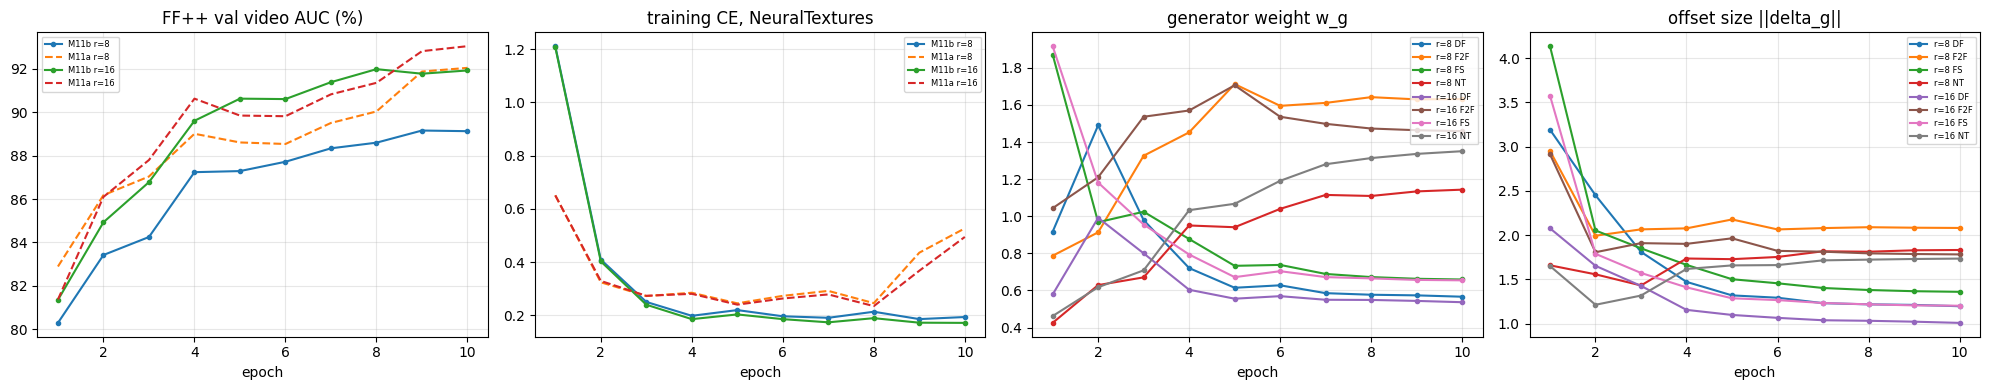

In [13]:
# 5.2 Curves
assert histories, "no finished ranks"
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for r, hist in histories.items():
    h = pd.DataFrame(hist)
    axes[0].plot(h.epoch, h["val video AUC"], marker=".", label=f"M11b r={r}")
    axes[1].plot(h.epoch, h["CE NT"], marker=".", label=f"M11b r={r}")
    a = M11A_DIR / f"sbln_r{r}_{ARCH}_seed{SEED}" / "results.json"
    if a.exists():
        ha = pd.DataFrame(json.loads(a.read_text())["history"])
        axes[0].plot(ha.epoch, ha["val video AUC"], ls="--", label=f"M11a r={r}")
        axes[1].plot(ha.epoch, ha["CE NT"], ls="--", label=f"M11a r={r}")
    for g in TRAIN_GENERATORS:
        axes[2].plot(h.epoch, h[f"w {SHORT[g]}"], marker=".", label=f"r={r} {SHORT[g]}")
        axes[3].plot(h.epoch, h[f"|d| {SHORT[g]}"], marker=".", label=f"r={r} {SHORT[g]}")
axes[0].set_title("FF++ val video AUC (%)"); axes[1].set_title("training CE, NeuralTextures")
axes[2].set_title("generator weight w_g"); axes[3].set_title("offset size ||delta_g||")
for ax in axes:
    ax.set_xlabel("epoch"); ax.legend(fontsize=6); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(M11B_DIR / "curves.png", dpi=150); plt.show()

### 5.3 Criteria and summary

Primary (fixed before training): FaceShifter ≥ 92.0 and DFD ≥ 96.0. Secondary: NeuralTextures gained over SB-LN alone (M11a) at the same rank, and the gap left to full LayerNorms.

In [14]:
# 5.3 Criteria and summary
full = main_table.loc["full LayerNorms (M4 λ=∞)"]
verdict = {}
for r in sorted(histories):
    row = main_table.loc[f"M11b r={r}"]
    alone = main_table.loc[f"SB-LN r={r} alone (M11a)"] if f"SB-LN r={r} alone (M11a)" in main_table.index else None
    verdict[r] = {
        "deployed trainable": int(row.trainable),
        "FSh": round(row.FSh, 2), "FSh >= 92": bool(row.FSh >= CRITERIA["FSh"]),
        "DFD": round(row.DFD, 2), "DFD >= 96": bool(row.DFD >= CRITERIA["DFD"]),
        "NT": round(row.NT, 2),
        "NT gain vs M11a": round(row.NT - alone.NT, 2) if alone is not None else None,
        "NT gap vs full LN": round(row.NT - full.NT, 2),
        "seen gap vs full LN": round(row.seen - full.seen, 2),
    }
verdict_table = pd.DataFrame(verdict).T
display(verdict_table)
for r, v in verdict.items():
    status = "MEETS" if v["FSh >= 92"] and v["DFD >= 96"] else "DOES NOT MEET"
    gain = "n/a" if v["NT gain vs M11a"] is None else f"{v['NT gain vs M11a']:+.2f}"
    print(f"rank {r}: {status} the primary criteria (FSh {v['FSh']}, DFD {v['DFD']}); NT {v['NT']} "
          f"({gain} vs SB-LN alone, {v['NT gap vs full LN']:+.2f} vs full LayerNorms)")

(M11B_DIR / "summary.json").write_text(json.dumps({
    "question": "does the full method (SB-LN + private offsets + offset-weighted GBRA + prototype head) meet FSh >= 92 and DFD >= 96, and recover NeuralTextures",
    "parameters": param_report.reset_index().astype(str).to_dict("records"),
    "main_table": main_table.round(3).reset_index().astype(str).to_dict("records"),
    "criteria": CRITERIA, "verdict": {str(k): v for k, v in verdict.items()},
    "hyperparameters": {"lambda": LAMBDA, "alpha": ALPHA, "beta": BETA, "margin": MARGIN, "ema": EMA, "tau_init": TAU_INIT},
}, indent=2, ensure_ascii=False))

,deployed trainable,FSh,FSh >= 92,DFD,DFD >= 96,NT,NT gain vs M11a,NT gap vs full LN,seen gap vs full LN
8,17186,92.38,True,94.96,False,69.99,-7.09,-17.91,-5.36
16,34370,93.01,True,95.56,False,77.91,-3.3,-9.99,-2.75


rank 8: DOES NOT MEET the primary criteria (FSh 92.38, DFD 94.96); NT 69.99 (-7.09 vs SB-LN alone, -17.91 vs full LayerNorms)
rank 16: DOES NOT MEET the primary criteria (FSh 93.01, DFD 95.56); NT 77.91 (-3.30 vs SB-LN alone, -9.99 vs full LayerNorms)


3850